# **Análisis Exploratorio de Datos y Visualización de Datos**
Por: Angel Alvarado Carrasco

In [ ]:
from google.colab import drive
drive.mount("/content/drive/")

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/data_studentlist.csv", header="infer")
df.head(5)

,Name,Gender,Age,Grade,Absence,Bloodtype,Height,Weight
0,Jared Diamond,M,23,3,Y,O,165.3,68.2
1,Sarah O'Donnel,F,22,2,N,AB,170.1,53.0
2,Brian Martin,M,24,4,N,B,175.0,80.1
3,David Hassel,M,23,3,N,AB,182.1,85.7
4,Clara Rodriquez,F,20,1,Y,A,168.0,49.5


In [ ]:
df[df["Gender"]=="M"].Height.mean()

np.float64(172.41000000000003)

In [ ]:
df[df["Gender"]=="F"].Height.mean()

np.float64(166.64285714285714)

In [ ]:
df[df["Gender"]=="M"].Weight.mean()

np.float64(68.50000000000001)

In [ ]:
df[df["Gender"]=="F"].Weight.mean()

np.float64(50.44285714285714)

In [ ]:
df[df["Gender"]=="M"].Height.max()

182.1

In [ ]:
df[df["Gender"]=="F"].Height.min()

155.2

In [ ]:
df[(df["Height"]>175) & (df["Gender"]=="M")].Weight.min()

61.3

In [ ]:
df[(df["Height"]<160) & (df["Gender"]=="F")].Weight.max()

45.3

In [ ]:
df[df["Absence"]=="N"].Grade.mean()

np.float64(2.076923076923077)

In [ ]:
df[df["Absence"]=="Y"].Grade.mean()

np.float64(3.0)

In [ ]:
df[df["Bloodtype"]=="A"].Height.mean()

np.float64(169.075)

In [ ]:
df[((df["Bloodtype"]=="A")  |  (df["Bloodtype"] == "AB")) & (df["Gender"] == "M")].Height.mean()

np.float64(173.375)

In [ ]:
df[(df['Absence']=="Y") & (df["Grade"]>=3)].Height.mean()

np.float64(167.0)

Tarea 2

In [ ]:
df_2 = pd.read_csv("/content/drive/MyDrive/data_census.csv")
df_2.head(5)

,Province Code,City Code,Population,Households,Person's Household,Gender Ratio
0,109,1001,"10,078,850","4,197,478",2.40,0.97
1,109,1188,"155,695","72,882",2.14,0.98
2,109,1189,"126,817","59,614",2.13,1.00
3,109,1158,"235,186","108,138",2.17,0.94
4,109,1105,"298,145","126,915",2.35,0.99


In [ ]:
df_2["Population"] = df_2["Population"].str.replace(",","").astype(float)

In [ ]:
df_2[(df_2["Province Code"]==115) | (df_2["Province Code"]==116)].Population.sum()

np.float64(5970327.0)

In [ ]:
df_2[df_2["Gender Ratio"] > 1].Population.mean()

np.float64(419221.2076923077)

In [ ]:
df_2.sort_values(by='Households', ascending=True).head(10)

,Province Code,City Code,Population,Households,Person's Household,Gender Ratio
52,112,1001,2914271.0,"1,145,232",2.54,1.01
228,104,1001,2697791.0,"1,160,150",2.33,1.01
254,103,1001,3356540.0,"1,356,430",2.47,1.02
26,108,1001,3517491.0,"1,430,441",2.46,0.98
200,114,1179,23308.0,"10,877",2.14,0.98
266,103,1010,252823.0,"100,073",2.53,1.12
256,103,1201,258719.0,"100,745",2.57,1.04
37,108,1042,248177.0,"101,090",2.46,0.97
70,107,1064,242758.0,"101,201",2.40,1.02
230,104,1226,246634.0,"101,508",2.43,1.06


In [ ]:
df_2[(df_2["Gender Ratio"] > 1) & (df_2["Person's Household"]<2)]

,Province Code,City Code,Population,Households,Person's Household,Gender Ratio
62,112,1155,20825.0,"11,172",1.86,1.29
149,101,1240,26790.0,"13,433",1.99,1.27
152,101,1017,30066.0,"15,485",1.94,1.15
167,117,1033,38027.0,"19,145",1.99,1.03
227,113,1120,43566.0,"22,248",1.96,1.11
253,104,1163,10304.0,"5,365",1.92,1.15


Tarea 3

In [ ]:
df_3 = pd.read_csv("/content/drive/MyDrive/data_sales.csv", header="infer")
df_3.head(5)

,Date,Region,Item,Unit Price,Units
0,04-Jul-14,East,Pen Set,4.99,62
1,12-Jul-14,East,Binder,1.99,29
2,21-Jul-14,Central,Pen Set,12.49,55
3,29-Jul-14,East,Binder,19.99,81
4,07-Aug-14,Central,Pen Set,23.95,42


In [ ]:
df_3["Amount"] = df_3["Unit Price"] * df_3["Units"]
df_3["Amount"].head(5)

,Amount
0,309.38
1,57.71
2,686.95
3,1619.19
4,1005.90


In [ ]:
df_3.groupby("Region", sort=True)[["Unit Price"]].agg(["mean"])

,Unit Price
,mean
Region,
Central,18.018750
East,9.143846
West,53.658333


In [ ]:
df_3.pivot_table(values="Unit Price",columns=["Region"], aggfunc="mean")

Region,Central,East,West
Unit Price,18.01875,9.143846,53.658333


In [ ]:
df_3.pivot_table(values="Units", columns=["Region", "Item"], aggfunc="sum", fill_value=0)

Region Central                           East                       West       \
Item    Binder Desk Pen Pen Set Pencil Binder  Pen Pen Set Pencil Binder Desk   
Units      424    7  27     243    498    234  175     152    130     64    3   

Region             
Item   Pen Pencil  
Units   76     88

In [ ]:
df_3.pivot_table(values="Amount", columns=["Region", "Item"], aggfunc="sum", fill_value=0)

Region  Central                                      East                    \
Item     Binder   Desk     Pen  Pen Set   Pencil   Binder      Pen  Pen Set   
Amount  5762.63  875.0  539.73  2421.39  1540.32  2535.66  1354.25  1748.48   

Region            West                         
Item   Pencil   Binder   Desk     Pen  Pencil  
Amount  363.7  1279.36  825.0  151.24  231.12

Texto 4

In [ ]:
df_4 = pd.read_csv("/content/drive/MyDrive/data_coffeeshop.csv", header="infer", na_values=[" "])
df_4.head(5)

,Year of Start,Current State,Size of Site
0,2008.0,In,20.80
1,2010.0,In,212.72
2,2013.0,In,20.04
3,2012.0,In,64.17
4,2002.0,Out,11.40


In [ ]:
valores = df_4["Year of Start"].value_counts().sort_index()
valores.size

47

In [ ]:

df_4["Year of Start"].value_counts().keys().sort_values()

Index([1964.0, 1966.0, 1967.0, 1968.0, 1969.0, 1970.0, 1971.0, 1972.0, 1974.0,
       1975.0, 1976.0, 1979.0, 1980.0, 1981.0, 1982.0, 1983.0, 1984.0, 1985.0,
       1986.0, 1987.0, 1988.0, 1989.0, 1990.0, 1991.0, 1992.0, 1993.0, 1994.0,
       1995.0, 1996.0, 1997.0, 1998.0, 1999.0, 2000.0, 2001.0, 2002.0, 2003.0,
       2004.0, 2005.0, 2006.0, 2007.0, 2008.0, 2009.0, 2010.0, 2011.0, 2012.0,
       2013.0, 2014.0],
      dtype='float64', name='Year of Start')

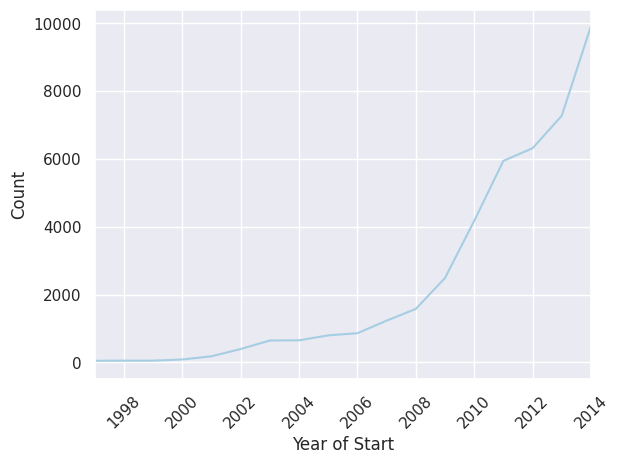

In [ ]:
plt.plot(df_4["Year of Start"].value_counts().keys().sort_values(), df_4['Year of Start'].value_counts().sort_values())
plt.
plt.xlim((1997,2014))
plt.xlabel("Year of Start")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [ ]:
#.value_counts(dropna=False).sort_values()
valores_in = df_4[df_4["Current State"]=="In"]["Year of Start"].value_counts(dropna=True).reindex(df_4["Year of Start"].unique(), fill_value=0).sort_index()
valores_in = valores_in.drop(np.nan)

In [ ]:
valores_out = df_4[df_4["Current State"]=="Out"]["Year of Start"].value_counts(dropna=True).reindex(df_4["Year of Start"].unique(), fill_value=0).sort_index()
valores_out = valores_out.drop(np.nan)

/tmp/ipykernel_2592/4049912460.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


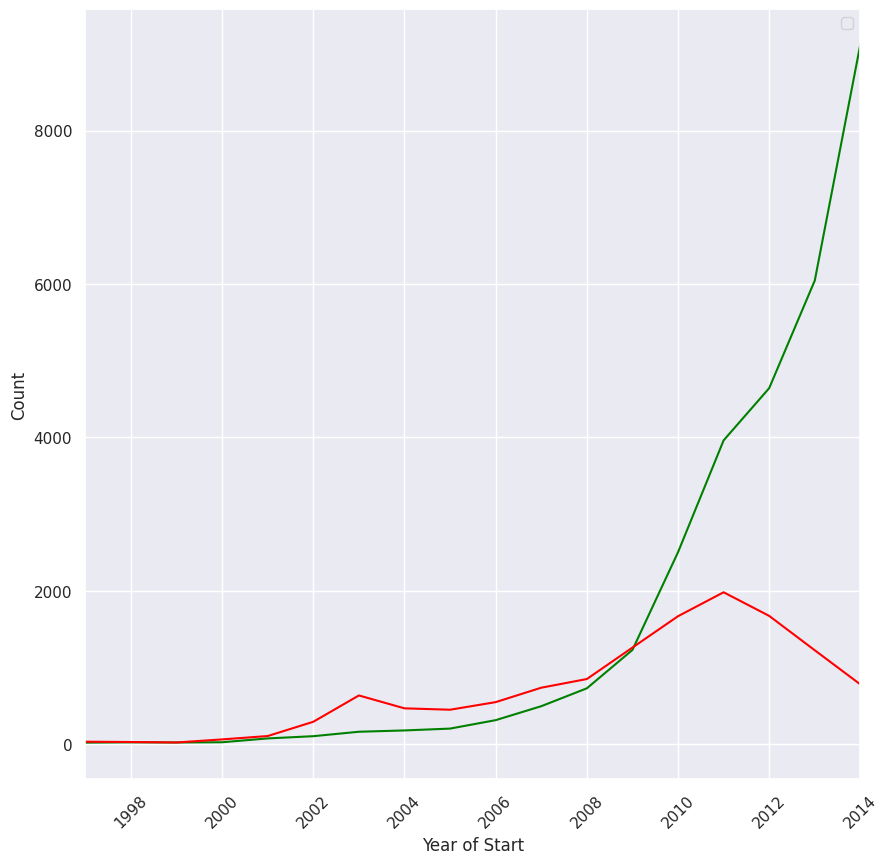

In [ ]:
Vfrom matplotlib import legend
plt.figure(figsize=(10,10))
sns.set_theme(palette="Paired")
plt.plot(df_4["Year of Start"].value_counts().keys().sort_values(), valores_in, color="Green")
plt.plot(df_4["Year of Start"].value_counts().keys().sort_values(), valores_out, color="Red")
plt.xlim((1997,2014))
plt.xlabel("Year of Start")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

